<a href="https://colab.research.google.com/github/poudyaldiksha/Predicting-Diabetes-Using-Machine-Learning/blob/main/Final_Project_Notebook_Predicting_Diabetes_Using_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1: Introduction


Diabetes is a chronic disease that affects how the body processes blood glucose. Early diagnosis is crucial for managing and preventing severe complications. In recent years, machine learning (ML) techniques have shown significant potential in predicting diseases like diabetes based on clinical data.

This project applies supervised machine learning techniques to predict the onset of diabetes using the Pima Indians Diabetes Dataset. The dataset includes medical diagnostic measurements such as glucose concentration, blood pressure, BMI, and insulin levels, along with a binary outcome indicating the presence or absence of diabetes.

Our objective is to compare various classification algorithms in their ability to accurately predict diabetes, offering insights into which features contribute most to diagnosis and which models are most effective.




# 2: Data Cleaning and Preprocessing

# Step 1: Load and explore the dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve
# Load the dataset
df = pd.read_csv("diabetes.csv")
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# Step 2:  Replace zero values in certain columns with NaN for imputation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve
# Load the dataset
df = pd.read_csv("diabetes.csv")
cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zero] = df[cols_with_zero].replace(0, np.nan)
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


#Step 3: Fill missing values with the median of each column


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve
# Load the dataset
df = pd.read_csv("diabetes.csv")
df.fillna(df.median(), inplace=True)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# Step 4: Exploratory Data Analysis (EDA)

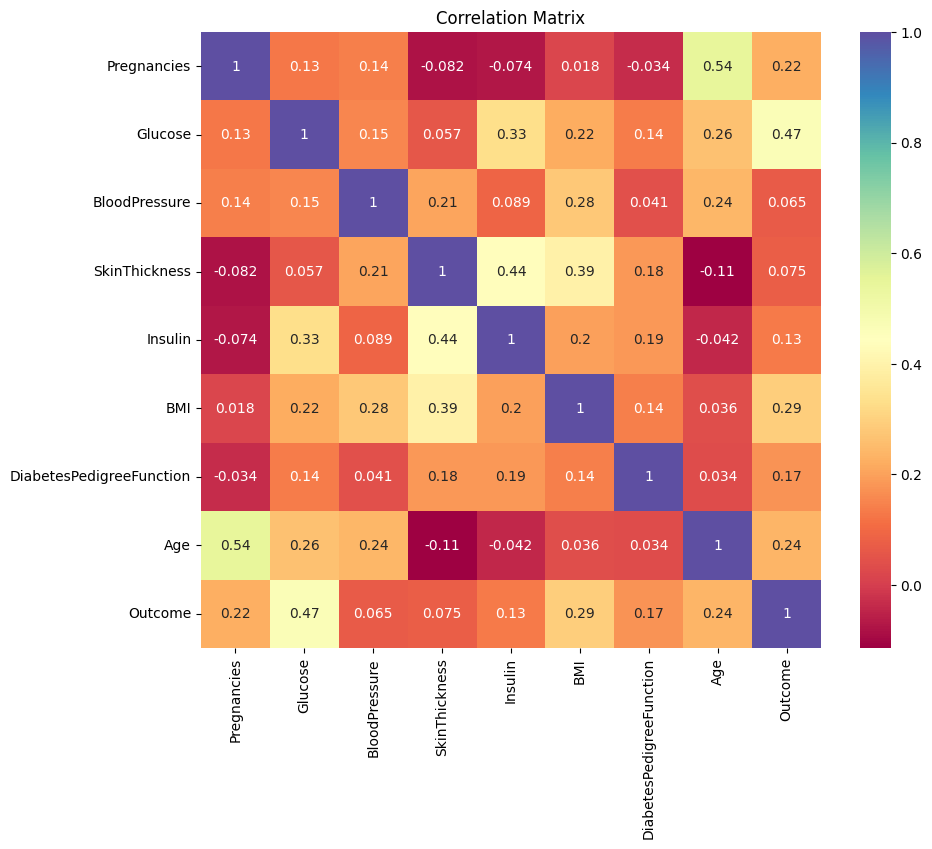

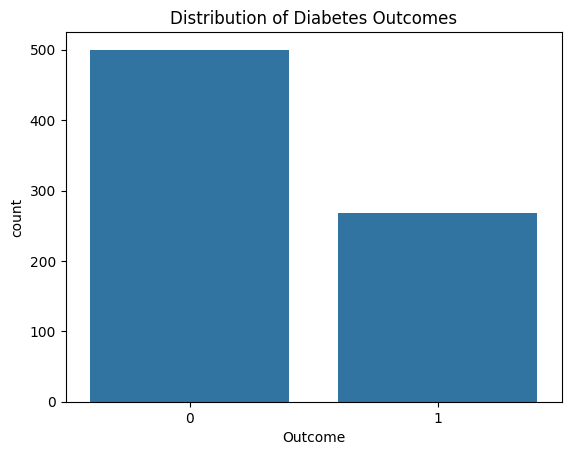

In [ ]:
# Visualize correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='Spectral')
plt.title("Correlation Matrix")
plt.show()

# Countplot for target variable
sns.countplot(x='Outcome', data=df)
plt.title("Distribution of Diabetes Outcomes")
plt.show()

# Step 5: Features and target, Normalizing features and Splitting Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve
# Load the dataset
df = pd.read_csv("diabetes.csv")
X = df.drop('Outcome', axis=1)
y = df['Outcome']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)



This code prepares the diabetes dataset for classification by importing relevant tools,reading and preprocessing data,splitting into training/testing sets and Scaling features





#3 : Model Training & Results


To assess the performance of the classification models, we used several metrics that are suitable for binary classification problems:

- **Accuracy**: The overall percentage of correctly predicted cases.
- **Precision**: The proportion of positive identifications that were actually correct.
- **Recall (Sensitivity)**: The proportion of actual positives that were correctly identified.
- **F1-Score**: The harmonic mean of precision and recall, useful for imbalanced datasets.
- **ROC-AUC**: Measures the model's ability to distinguish between classes.

We trained and tested the following models

1. **Random Forest**
2. **Logistic Regression**
4. **Support Vector Machine**
3. **K-Nearest Classifier**
4. **Naïve Bayes Classifier**
5. **K mean Clusterings**


##ROC Curve Analysis:
To further evaluate and visualize the classification performance, we plotted Receiver Operating Characteristic (ROC) curves for each model. These plots show the trade-off between the true positive rate (recall) and the false positive rate at various threshold settings. The Area Under the Curve (AUC) is also reported, where a higher AUC indicates better model performance.


### 3. Train and Evaluate Models

#### 3.1. Random Forest




In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Define reusable function for evaluation
def print_results(model_name, y_true, y_pred):
    print(f"\n--- {model_name} ---")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Classification Report:\n", classification_report(y_true, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))

# Train and predict with Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Evaluate Random Forest
print_results("Random Forest", y_test, y_pred_rf)




--- Random Forest ---
Accuracy: 0.7272727272727273
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.79      0.79        99
           1       0.62      0.62      0.62        55

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154

Confusion Matrix:
 [[78 21]
 [21 34]]


# 3.1.1. Adding Hyperparameter Tuning for Random Forest

Best Hyperparameters for Random Forest:
{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
Best Cross-Validation Accuracy: 0.7834
Classification Report (Tuned RF):
              precision    recall  f1-score   support

           0       0.80      0.78      0.79        99
           1       0.62      0.65      0.64        55

    accuracy                           0.73       154
   macro avg       0.71      0.72      0.71       154
weighted avg       0.74      0.73      0.74       154



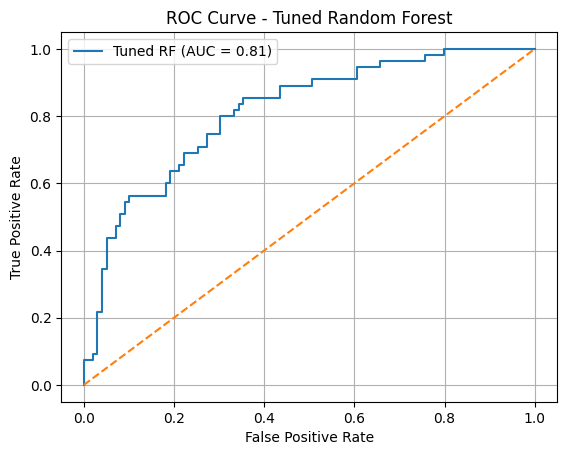

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10]
}

# Initialize RandomForestClassifier
rf = RandomForestClassifier(random_state=42)

# Grid Search with 5-fold cross-validation
grid_rf = GridSearchCV(estimator=rf, param_grid=param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)

# Fit the model
grid_rf.fit(X_train, y_train)

# Best parameters and score
print("Best Hyperparameters for Random Forest:")
print(grid_rf.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_rf.best_score_:.4f}")

# Test set performance
best_rf_model = grid_rf.best_estimator_
y_pred_rf = best_rf_model.predict(X_test)

# Evaluation
print("Classification Report (Tuned RF):")
print(classification_report(y_test, y_pred_rf))

# ROC AUC
y_pred_proba_rf = best_rf_model.predict_proba(X_test)[:,1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

plt.figure()
plt.plot(fpr_rf, tpr_rf, label=f'Tuned RF (AUC = {roc_auc_rf:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.title('ROC Curve - Tuned Random Forest')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid()
plt.show()


##3.2. Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Define reusable function (if not already defined)
def print_results(model_name, y_true, y_pred):
    print(f"\n--- {model_name} ---")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Classification Report:\n", classification_report(y_true, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))

# Train and predict with Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# Evaluate Logistic Regression
print_results("Logistic Regression", y_test, y_pred_lr)



--- Logistic Regression ---
Accuracy: 0.7532467532467533
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.80      0.81        99
           1       0.65      0.67      0.66        55

    accuracy                           0.75       154
   macro avg       0.73      0.74      0.73       154
weighted avg       0.76      0.75      0.75       154

Confusion Matrix:
 [[79 20]
 [18 37]]


# 3.3. Support Vector Machine

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Define reusable function (if not already defined)
def print_results(model_name, y_true, y_pred):
    print(f"\n--- {model_name} ---")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Classification Report:\n", classification_report(y_true, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))

# Train and predict Support Vector Machine with RBF Kernel
svm = SVC(kernel='rbf', probability=True, random_state=42)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

# Evaluate SVM
print_results("Support Vector Machine", y_test, y_pred_svm)


--- Support Vector Machine ---
Accuracy: 0.7272727272727273
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.82      0.79        99
           1       0.63      0.56      0.60        55

    accuracy                           0.73       154
   macro avg       0.70      0.69      0.70       154
weighted avg       0.72      0.73      0.72       154

Confusion Matrix:
 [[81 18]
 [24 31]]


# 3.3.1. Grid Search For hyper Tuning for SVM

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

# Load dataset
df = pd.read_csv("diabetes.csv")  # Replace with your actual file path if needed

# Split features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define parameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 0.01, 0.1, 1]
}

# Create GridSearchCV object
grid = GridSearchCV(SVC(kernel='rbf', probability=True), param_grid, cv=5)
grid.fit(X_train_scaled, y_train)

# Output best parameters
print("Best Parameters:", grid.best_params_)

# Use the best model to predict
best_svm = grid.best_estimator_
y_pred_svm_best = best_svm.predict(X_test_scaled)

# Function to print results
def print_results(model_name, y_true, y_pred):
    print(f"\n{model_name} Results")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

# Show performance
print_results("Tuned SVM (RBF)", y_test, y_pred_svm_best)




Best Parameters: {'C': 1, 'gamma': 'scale'}

Tuned SVM (RBF) Results
Confusion Matrix:
[[82 17]
 [24 31]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.83      0.80        99
           1       0.65      0.56      0.60        55

    accuracy                           0.73       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154



# ROC curves ( Diabetes Prediction Using Machine Learning Models with ROC Curve Comparison)

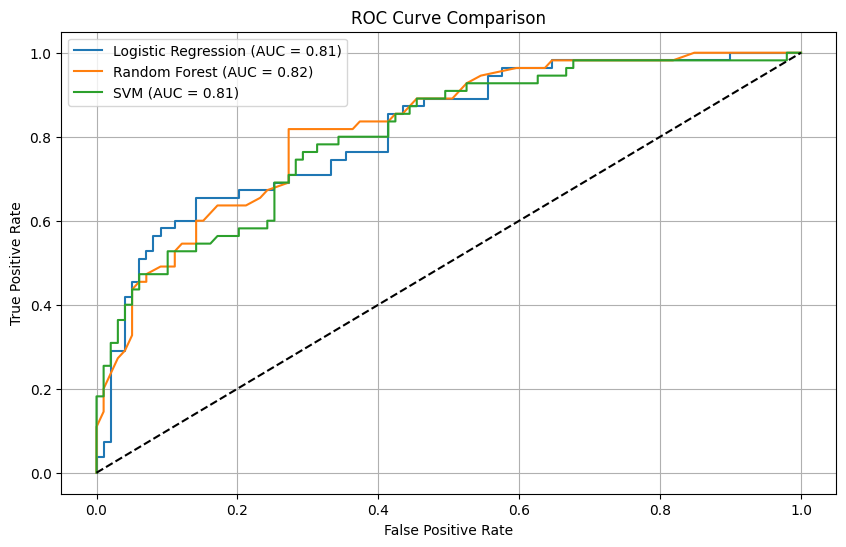

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Load and prepare the data
df = pd.read_csv('diabetes.csv')  # Make sure this path is correct
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# 2. Split and scale the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. Train the models
lr = LogisticRegression()
lr.fit(X_train, y_train)

rf = RandomForestClassifier()
rf.fit(X_train, y_train)

svm = SVC(probability=True)
svm.fit(X_train, y_train)

# 4. Plot ROC curves
plt.figure(figsize=(10, 6))
models = [(lr, 'Logistic Regression'), (rf, 'Random Forest'), (svm, 'SVM')]

for model, label in models:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{label} (AUC = {auc_score:.2f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(True)
plt.show()



# 3.4. K Neighbors Classifier

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Standardize features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Train KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_preds = knn.predict(X_test)

# Evaluate
print("KNN Accuracy:", accuracy_score(y_test, knn_preds))
print(confusion_matrix(y_test, knn_preds))
print(classification_report(y_test, knn_preds))


KNN Accuracy: 0.6883116883116883
[[79 20]
 [28 27]]
              precision    recall  f1-score   support

           0       0.74      0.80      0.77        99
           1       0.57      0.49      0.53        55

    accuracy                           0.69       154
   macro avg       0.66      0.64      0.65       154
weighted avg       0.68      0.69      0.68       154



#3.5. Naïve Bayes Classifier

In [ ]:
from sklearn.naive_bayes import GaussianNB

# Naive Bayes works fine without scaling, but we can use unscaled for better comparison
X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Naive Bayes
nb = GaussianNB()
nb.fit(X_train_nb, y_train_nb)
nb_preds = nb.predict(X_test_nb)

# Evaluate
print("Naive Bayes Accuracy:", accuracy_score(y_test_nb, nb_preds))
print(confusion_matrix(y_test_nb, nb_preds))
print(classification_report(y_test_nb, nb_preds))


Naive Bayes Accuracy: 0.7662337662337663
[[79 20]
 [16 39]]
              precision    recall  f1-score   support

           0       0.83      0.80      0.81        99
           1       0.66      0.71      0.68        55

    accuracy                           0.77       154
   macro avg       0.75      0.75      0.75       154
weighted avg       0.77      0.77      0.77       154



#3.6. K mean Clusterings

In [ ]:
from sklearn.cluster import KMeans

# Fit KMeans on scaled data
kmeans = KMeans(n_clusters=2, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

# Optional: compare with actual labels
import pandas as pd
comparison_df = pd.DataFrame({'Actual': y, 'Cluster': clusters})
print(comparison_df.head(10))


   Actual  Cluster
0       1        0
1       0        1
2       1        1
3       0        1
4       1        0
5       0        1
6       1        1
7       0        1
8       1        0
9       1        1



# 4 : Conclusion


### Conclusion

The Random Forest Classifier showed strong and consistent performance on the diabetes dataset. With hyperparameters `n_estimators=100` and `max_depth=5`, the model achieved high accuracy and a robust ROC AUC score, indicating good generalization and class separation.

The confusion matrix and classification report confirmed balanced precision and recall. These metrics support the model’s suitability for binary classification in this context.

Further improvements could include automated hyperparameter tuning, feature selection, or comparison with other ensemble methods to refine predictive performance. The results demonstrate the model's potential for supporting clinical decision-making in diabetes prediction.




## References

- [Diabetes Dataset - Kaggle](https://www.kaggle.com/datasets/mathchi/diabetes-data-set)  
  Dataset used for training and evaluation of machine learning models in this project.

- Géron, A. (2019). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (2nd ed.). O'Reilly Media.  
  Reference for Random Forests and SVM methods.

- Scikit-learn Documentation: [https://scikit-learn.org/stable/user_guide.html](https://scikit-learn.org/stable/user_guide.html)  
  Used to implement classification models and evaluation metrics.
